## Question 1

## 1.1 Load the data and denoise the text

In [1]:
# Imports
import re
import string
import unicodedata
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download the NLTK resources we need (quietly)
for pkgName in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkgName, quiet=True)

In [2]:
# Load the dataset
# Try a normal JSON array first, fall back to JSON-lines if that fails
try:
    df = pd.read_json("../data/research_abstracts.json")
except ValueError:
    df = pd.read_json("../data/research_abstracts.json", lines=True)

print(df.shape)
df.info()
print(df.head())

(1138, 3)
<class 'pandas.core.frame.DataFrame'>
Index: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DOI       1134 non-null   object
 1   Abstract  1138 non-null   object
 2   Label     1138 non-null   object
dtypes: object(3)
memory usage: 35.6+ KB
                          DOI  \
0        10.1155/2021/1071145   
1  10.1007/s43546-022-00384-2   
2            10.1002/for.2667   
3  10.1007/s42973-021-00091-x   
4   10.1007/s40258-012-0003-z   

                                            Abstract      Label  
0  Forward-looking forecasting of the inflation r...         ai  
1  Our study examined the disaggregation of infla...         ai  
2  This paper develops a dynamic factor model tha...  classical  
3  In this paper, I use a simple SIR Macro model ...  classical  
4  BackgroundGame theory is useful for identifyin...  classical  


In [3]:
# Quick data quality check
print("Missing values:\n", df.isna().sum())
print("\nDuplicate DOIs:", df["DOI"].duplicated().sum())
print("Duplicate abstracts:", df["Abstract"].duplicated().sum())
print("\nLabel counts:\n", df["Label"].value_counts())

Missing values:
 DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate DOIs: 3
Duplicate abstracts: 13

Label counts:
 Label
classical    900
ai           238
Name: count, dtype: int64


In [4]:
# Check that duplicate abstracts don't have conflicting labels
dupRows = df[df["Abstract"].duplicated(keep=False)]
conflictCount = (dupRows.groupby("Abstract")["Label"].nunique() > 1).sum()
print("Duplicate abstracts with conflicting labels:", conflictCount)

Duplicate abstracts with conflicting labels: 0


In [5]:
# Denoising / text cleaning

# Remove duplicate abstracts (none had conflicting labels, so this is safe)
df = df.drop_duplicates(subset="Abstract").reset_index(drop=True)

stopWords = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def cleanText(text):
    # Normalise unicode: é -> e, non-breaking space -> space
    text = unicodedata.normalize("NFKD", text)
    # Drop leftover non-ASCII symbols (smart quotes, ©, etc.)
    text = text.encode("ascii", "ignore").decode()
    # Fix section headers glued to the text, e.g. "BackgroundGame" -> "Background Game"
    text = re.sub(r"\b(Background|Objectives?|Methods?|Results|Conclusions?|Purpose)(?=[A-Z])", r"\1 ", text)
    # Remove publisher boilerplate sentences
    text = re.sub(r"[^.]*(download this paper|www\.nber\.org)[^.]*\.", " ", text, flags=re.I)
    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # Remove citation markers like [1] or [2,3]
    text = re.sub(r"\[\d+(?:[,\-]\s*\d+)*\]", " ", text)
    # Remove copyright lines
    text = re.sub(r"copyright\s*\d{4}[^.]*\.", " ", text, flags=re.I)
    # Lowercase
    text = text.lower()
    # Remove numbers
    text = re.sub(r"\d+", " ", text)
    # Replace punctuation with spaces
    text = text.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))
    # Remove stopwords and very short tokens, then lemmatize
    return " ".join(lemmatizer.lemmatize(word) for word in text.split()
                    if word not in stopWords and len(word) > 2)

df["cleanText"] = df["Abstract"].apply(cleanText)

# Drop any rows that ended up empty after cleaning
df = df[df["cleanText"].str.len() > 0].reset_index(drop=True)

# Before vs after check
print(df.shape)
print("BEFORE:", df["Abstract"].iloc[0][:300])
print("AFTER: ", df["cleanText"].iloc[0][:300])
print("Avg words before:", df["Abstract"].str.split().str.len().mean())
print("Avg words after:", df["cleanText"].str.split().str.len().mean())

(1125, 4)
BEFORE: Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutio
AFTER:  forward looking forecasting inflation rate could help central bank government department better use monetary policy stabilize price prevent impact inflation market entity especially low middle income group also help financial institution investor better make investment decision sense forecast inflat
Avg words before: 171.59466666666665
Avg words after: 104.25866666666667


**1.1 Answer – denoising techniques applied:**
- Duplicate abstract removal (13 duplicates, none with conflicting labels)
- Unicode normalisation (accents, non-breaking spaces, smart quotes)
- Removal of boilerplate (e.g. "download this paper at www.nber.org"), URLs, citation markers (`[1]`) and copyright lines
- Fixing section headers glued to text (e.g. `BackgroundGame`)
- Lowercasing, number removal and punctuation removal
- Stopword removal and removal of very short tokens
- Lemmatization

Result: 1138 rows reduced to 1125 and average abstract length reduced from about 172 to about 104 words.

## 1.2 Identify relevant columns for feature engineering

In [6]:
# Check the columns and class balance
print(df.columns.tolist())
print(df["Label"].value_counts())

['DOI', 'Abstract', 'Label', 'cleanText']
Label
classical    890
ai           235
Name: count, dtype: int64


In [7]:
# Feature modelling: TF-IDF + chi-square
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
import numpy as np

# Encode the target: ai = 1, classical = 0
df["labelEnc"] = (df["Label"] == "ai").astype(int)

# Turn the cleaned text into TF-IDF features (unigrams + bigrams)
tfidfVec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
xAll = tfidfVec.fit_transform(df["cleanText"])
yAll = df["labelEnc"]
print("TF-IDF matrix shape:", xAll.shape)

# Chi-square test: which terms best separate ai from classical?
chiScores, pValues = chi2(xAll, yAll)
termNames = np.array(tfidfVec.get_feature_names_out())
topIdx = np.argsort(chiScores)[::-1][:20]
for term, score in zip(termNames[topIdx], chiScores[topIdx]):
    print(f"{term:30s} {score:.2f}")
print("Terms with p < 0.05:", (pValues < 0.05).sum(), "of", len(termNames))

TF-IDF matrix shape: (1125, 8190)
machine                        22.13
neural                         20.76
network                        20.35
machine learning               20.34
neural network                 20.31
learning                       19.86
algorithm                      15.99
lstm                           11.00
forest                         9.00
svr                            8.84
ann                            8.69
artificial                     8.62
random forest                  8.58
quantile                       8.24
learning model                 7.49
sentiment                      7.40
artificial neural              7.02
learning algorithm             6.89
mse                            6.84
tree                           6.37
Terms with p < 0.05: 47 of 8190


**1.2 Answer – column selection:**
- `cleanText` (from `Abstract`): **feature source**, the only column with semantic content.
- `Label`: **target** (`ai` = 1, `classical` = 0).
- `DOI`: **dropped**. It is just an identifier with no semantic meaning and could leak publisher information (e.g. `10.1016` = Elsevier).
- `Abstract`: **dropped**, it is the raw version of `cleanText` (redundant).

**Feature modelling:** TF-IDF (unigrams and bigrams) converts the text to numeric features, and a chi-square test identifies which terms carry signal for the label. The top terms (machine, neural, network, learning, lstm, forest, svr, ann) are all ML vocabulary, as expected for the `ai` class. Only 47 of 8190 terms are significant at p < 0.05, so the signal is concentrated in a small set of terms.

## 1.3 Baseline model, performance report, and comment

In [8]:
# Imports for modelling
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

In [9]:
# Stratified train/test split (keeps the 79/21 class ratio in both sets)
xTrain, xTest, yTrain, yTest = train_test_split(
    df["cleanText"], df["labelEnc"],
    test_size=0.2, stratify=df["labelEnc"], random_state=42
)

# Baseline model: TF-IDF + Logistic Regression
# TF-IDF sits inside the pipeline so it is only fitted on training data (no leakage)
baselineModel = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])
baselineModel.fit(xTrain, yTrain)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.9, min_df=3, ngram_range=(1, 2),
                                 sublinear_tf=True)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [10]:
# Learning vs generalization: train vs test
trainPred = baselineModel.predict(xTrain)
testPred = baselineModel.predict(xTest)
print("Train acc:", round(accuracy_score(yTrain, trainPred), 3), "| F1:", round(f1_score(yTrain, trainPred), 3))
print("Test  acc:", round(accuracy_score(yTest, testPred), 3), "| F1:", round(f1_score(yTest, testPred), 3))

# 5-fold stratified cross-validation (F1 on the ai class)
cvSplitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cvF1 = cross_val_score(baselineModel, xTrain, yTrain, cv=cvSplitter, scoring="f1")
print("5-fold CV F1:", cvF1.round(3), "| mean:", round(cvF1.mean(), 3), "| std:", round(cvF1.std(), 3))

# Full performance report on the test set
print("\nClassification report (test):\n",
      classification_report(yTest, testPred, target_names=["classical", "ai"]))
print("Confusion matrix (test):\n", confusion_matrix(yTest, testPred))

Train acc: 0.984 | F1: 0.964
Test  acc: 0.871 | F1: 0.701
5-fold CV F1: [0.838 0.747 0.73  0.806 0.74 ] | mean: 0.772 | std: 0.042

Classification report (test):
               precision    recall  f1-score   support

   classical       0.93      0.91      0.92       178
          ai       0.68      0.72      0.70        47

    accuracy                           0.87       225
   macro avg       0.80      0.82      0.81       225
weighted avg       0.87      0.87      0.87       225

Confusion matrix (test):
 [[162  16]
 [ 13  34]]


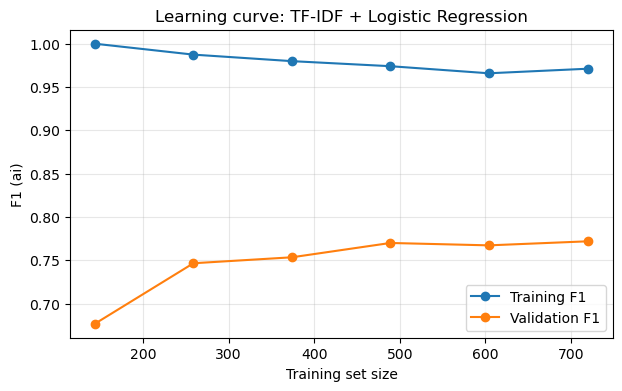

In [11]:
# Learning curve: how do train/validation F1 change with more data?
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

trainSizes, trainScores, valScores = learning_curve(
    baselineModel, xTrain, yTrain, cv=cvSplitter, scoring="f1",
    train_sizes=np.linspace(0.2, 1.0, 6), random_state=42
)

plt.figure(figsize=(7, 4))
plt.plot(trainSizes, trainScores.mean(axis=1), "o-", label="Training F1")
plt.plot(trainSizes, valScores.mean(axis=1), "o-", label="Validation F1")
plt.xlabel("Training set size")
plt.ylabel("F1 (ai)")
plt.title("Learning curve: TF-IDF + Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**1.3 Answer – comment on model performance:**

| | Train | Test |
|---|---|---|
| Accuracy | 0.984 | 0.871 |
| F1 (ai) | 0.964 | 0.701 |

5-fold CV F1 = 0.772 ± 0.042. Test confusion matrix: 162 TN, 16 FP, 13 FN, 34 TP.

- **Learning:** the model fits the training data very well (F1 0.964), so it learns the vocabulary patterns easily.
- **Generalization:** test F1 drops to 0.701 and CV F1 averages 0.772, a gap of roughly 0.2 from training. This indicates **overfitting**, typical for ~8k TF-IDF features on only ~900 training abstracts.
- **Stability:** CV F1 ranges from 0.73 to 0.84, so results vary by split. With only 235 `ai` samples, the single test F1 is a noisy estimate.
- **Class performance:** `classical` performs well (F1 0.92); `ai` is weaker (precision 0.68, recall 0.72). Accuracy (0.87) flatters the model because of the 79/21 imbalance, so F1 on `ai` is the fairer metric.
- **Errors:** 16 false positives and 13 false negatives are roughly balanced, so `class_weight="balanced"` worked as intended.
- **Learning curve:** training F1 stays at ~0.97 while validation F1 rises from ~0.68 to ~0.77 and plateaus. The large persistent gap shows high variance (overfitting), and more data alone would help only marginally.
- **Conclusion:** a reasonable baseline, but it overfits. Stronger regularisation (lower `C`), fewer features, or a different model would be the next improvements.

## Refernces used to help answer this Question

#### I also used AI (DeepSeek) to help  me understand the questions and it also helped me formulate a response .I also used it to structure my code more neatly so that it is easier to read and understand.It also helped me interpret the output so that i could answer the following question based on the output of the previous

ApX (n.d.) Practice: preprocessing pipelines. Available at: https://apxml.com/courses/nlp-fundamentals/chapter-1-nlp-text-processing-techniques/practice-preprocessing-pipelines (Accessed: 10 October 2026).

Bird, S., Klein, E. and Loper, E. (2009) Natural language processing with Python. Sebastopol: O’Reilly Media. Available at: https://www.oreilly.com/library/view/natural-language-processing/9780596803346/ch03.html (Accessed: 10 October 2026).

DHRI Curriculum (n.d.) Data cleaning: lemmatizing words. Available at: https://github.com/DHRI-Curriculum/text-analysis/blob/v2.0/sections/10-data-cleaning-lemmatizing-words.md (Accessed: 10 October 2026).

joshtod (2016) PyCon 2016 tutorial. Available at: https://github.com/joshtod/pycon-2016-tutorial (Accessed: 10 October 2026).

Machine Learning Mastery (n.d.) The beginner’s guide to natural language processing with Python. Available at: https://machinelearningmastery.com/the-beginners-guide-to-natural-language-processing-with-python/ (Accessed: 10 October 2026).

scikit-learn developers (n.d.a) Common pitfalls and recommended practices. Available at: https://scikit-learn.org/stable/common_pitfalls.html (Accessed: 10 October 2026).

scikit-learn developers (n.d.b) scikit-learn tutorials. Available at: https://scikit-learn.org/stable/tutorial (Accessed: 10 October 2026).

scikit-learn developers (n.d.c) sklearn.feature_extraction.text.TfidfVectorizer. Available at: https://scikit-learn.org/dev/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html (Accessed: 10 October 2026).

scikit-learn developers (n.d.d) sklearn.feature_selection.chi2. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.chi2.html (Accessed: 10 October 2026).

scikit-learn developers (n.d.e) Validation curves: plotting scores to evaluate models. Available at: https://scikit-learn.org/dev/modules/learning_curve.html (Accessed: 10 October 2026).

# Question 2.1

In [12]:
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Same TF-IDF settings as the baseline, rebuilt for each model
def makeTfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)

# The four models to compare
modelDict = {
    "Complement NB": ComplementNB(),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

resultList = []

# Baseline first, so every model is compared against it
baseTrainPred = baselineModel.predict(xTrain)
baseTestPred = baselineModel.predict(xTest)
resultList.append({
    "Model": "Baseline (Logistic Regression)",
    "Train F1": f1_score(yTrain, baseTrainPred),
    "Test F1": f1_score(yTest, baseTestPred),
    "Test Acc": accuracy_score(yTest, baseTestPred),
    "CV F1 mean": cvF1.mean(),
    "CV F1 std": cvF1.std(),
})

# Train and evaluate each new model
for modelName, clfModel in modelDict.items():
    pipe = Pipeline([("tfidf", makeTfidf()), ("clf", clfModel)])
    pipe.fit(xTrain, yTrain)
    trainPred = pipe.predict(xTrain)
    testPred = pipe.predict(xTest)
    cvScores = cross_val_score(pipe, xTrain, yTrain, cv=cvSplitter, scoring="f1")
    resultList.append({
        "Model": modelName,
        "Train F1": f1_score(yTrain, trainPred),
        "Test F1": f1_score(yTest, testPred),
        "Test Acc": accuracy_score(yTest, testPred),
        "CV F1 mean": cvScores.mean(),
        "CV F1 std": cvScores.std(),
    })

# Comparison table, best CV F1 at the top
resultDf = pd.DataFrame(resultList).sort_values("CV F1 mean", ascending=False).round(3)
print(resultDf.to_string(index=False))

C:\Users\hamza\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\hamza\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\hamza\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\hamza\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
C:\Users\hamza\anaconda3\Lib\site-packages\sklearn\svm\_clas

                         Model  Train F1  Test F1  Test Acc  CV F1 mean  CV F1 std
                    Linear SVM     0.997    0.713     0.889       0.817      0.043
Baseline (Logistic Regression)     0.964    0.701     0.871       0.772      0.042
             Gradient Boosting     0.970    0.744     0.902       0.754      0.051
                 Random Forest     1.000    0.648     0.889       0.715      0.037
                 Complement NB     0.857    0.640     0.880       0.699      0.033


**2.1 Answer – model comparison:**

Four models (Complement Naive Bayes, Linear SVM, Random Forest, Gradient Boosting) were trained on the same TF-IDF features and stratified train/test split as the baseline. They were compared using test F1 (ai class), test accuracy and 5-fold cross-validated F1.

| Model | Train F1 | Test F1 | Test Acc | CV F1 mean | CV F1 std |
|---|---|---|---|---|---|
| Linear SVM | 0.997 | 0.713 | 0.889 | 0.817 | 0.043 |
| Baseline (Logistic Regression) | 0.964 | 0.701 | 0.871 | 0.772 | 0.042 |
| Gradient Boosting | 0.970 | 0.744 | 0.902 | 0.754 | 0.051 |
| Random Forest | 1.000 | 0.648 | 0.889 | 0.715 | 0.037 |
| Complement NB | 0.857 | 0.640 | 0.880 | 0.699 | 0.033 |

- **Linear SVM** performed best overall. It is the only model that beat the baseline on both test F1 (0.713 vs 0.701) and CV F1 (0.817 vs 0.772).
- **Gradient Boosting** had the highest test F1 (0.744) and accuracy (0.902), but its CV F1 (0.754) is only slightly above the baseline. With only 47 `ai` abstracts in the test set, the single test score is a noisy estimate.
- **Random Forest** fits the training data perfectly (F1 1.000) but scores below the baseline on F1, which indicates overfitting.
- **Complement Naive Bayes** had the lowest scores. Its simple independence assumptions suit this data less well.
- **Conclusion:** Linear SVM is selected as the best single model because it is the most consistent across cross-validation and the test set.

# 2.2

In [13]:
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV

# Ensemble: three different models vote by averaging their predicted probabilities
ensembleClf = VotingClassifier(
    estimators=[
        ("svm", CalibratedClassifierCV(LinearSVC(class_weight="balanced", dual=True, random_state=42), cv=3)),
        ("gb", GradientBoostingClassifier(random_state=42)),
        ("lr", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ],
    voting="soft",
)
ensembleModel = Pipeline([("tfidf", makeTfidf()), ("clf", ensembleClf)])
ensembleModel.fit(xTrain, yTrain)

# Best single model from 2.1, rebuilt for a fair comparison
svmModel = Pipeline([
    ("tfidf", makeTfidf()),
    ("clf", LinearSVC(class_weight="balanced", dual=True, random_state=42)),
])
svmModel.fit(xTrain, yTrain)

# Compare baseline vs best single model vs ensemble
compareList = []
for modelName, fittedModel in [("Baseline (Logistic Regression)", baselineModel),
                               ("Linear SVM", svmModel),
                               ("Soft-voting ensemble", ensembleModel)]:
    testPred = fittedModel.predict(xTest)
    cvScores = cross_val_score(fittedModel, xTrain, yTrain, cv=cvSplitter, scoring="f1")
    compareList.append({
        "Model": modelName,
        "Test F1": f1_score(yTest, testPred),
        "Test Acc": accuracy_score(yTest, testPred),
        "CV F1 mean": cvScores.mean(),
        "CV F1 std": cvScores.std(),
    })
print(pd.DataFrame(compareList).round(3).to_string(index=False))

# Detailed report for the ensemble
ensemblePred = ensembleModel.predict(xTest)
print("\nClassification report (ensemble, test):\n",
      classification_report(yTest, ensemblePred, target_names=["classical", "ai"]))
print("Confusion matrix (ensemble, test):\n", confusion_matrix(yTest, ensemblePred))

                         Model  Test F1  Test Acc  CV F1 mean  CV F1 std
Baseline (Logistic Regression)    0.701     0.871       0.772      0.042
                    Linear SVM    0.713     0.889       0.817      0.043
          Soft-voting ensemble    0.795     0.924       0.802      0.032

Classification report (ensemble, test):
               precision    recall  f1-score   support

   classical       0.93      0.98      0.95       178
          ai       0.92      0.70      0.80        47

    accuracy                           0.92       225
   macro avg       0.92      0.84      0.87       225
weighted avg       0.92      0.92      0.92       225

Confusion matrix (ensemble, test):
 [[175   3]
 [ 14  33]]


**2.2 Answer – additional enhancement approach: soft-voting ensemble**

Besides trying different models, I applied **ensemble learning**. Three different models (a calibrated Linear SVM, Gradient Boosting and Logistic Regression) each predict a probability, and the ensemble averages them ("soft voting"). Models make different kinds of errors, so averaging them cancels out some of the individual mistakes. The ensemble sits in the same pipeline as the TF-IDF step, so it is only fitted on training data (no leakage).

| Model | Test F1 | Test Acc | CV F1 mean | CV F1 std |
|---|---|---|---|---|
| Baseline (Logistic Regression) | 0.701 | 0.871 | 0.772 | 0.042 |
| Linear SVM | 0.713 | 0.889 | 0.817 | 0.043 |
| Soft-voting ensemble | 0.795 | 0.924 | 0.802 | 0.032 |

Ensemble test report: classical F1 = 0.95, ai F1 = 0.80 (precision 0.92, recall 0.70). Confusion matrix: 175 TN, 3 FP, 14 FN, 33 TP.

- **Improvement over the baseline:** test F1 rose from 0.701 to 0.795 and accuracy from 0.871 to 0.924. False positives dropped from 16 to 3, and precision on the `ai` class rose from 0.68 to 0.92, so abstracts labelled `ai` are now far more trustworthy.
- **Improvement over the best single model:** test F1 rose from 0.713 (Linear SVM) to 0.795. The ensemble also has the lowest CV standard deviation (0.032), so its performance varies less between splits.
- **Trade-off:** the ensemble's CV F1 (0.802) is slightly below the Linear SVM's (0.817), but within one standard deviation, so the difference is small. Recall on the `ai` class (0.70) is similar to the baseline (0.72), and 14 `ai` abstracts are still missed.
- **Conclusion:** the ensemble gives the best test performance and the most stable results, so it is selected as the final model for deployment.

# 2.3

In [14]:
import joblib
from sklearn.base import clone

# Retrain the final ensemble on all the cleaned data (the best model from 2.2)
finalModel = clone(ensembleModel)
finalModel.fit(df["cleanText"], df["labelEnc"])

# Save it so the web app can load it
joblib.dump(finalModel, "../deployment/researchlyModel.pkl")
print("Model saved")

# Quick sanity check: the saved model expects cleaned text, so clean it first
sampleText = "Machine learning algorithms and neural networks can analyse large volumes of medical data to improve diagnosis."
samplePred = finalModel.predict([cleanText(sampleText)])[0]
print("Prediction:", "artificial intelligence" if samplePred == 1 else "classical")

Model saved
Prediction: artificial intelligence


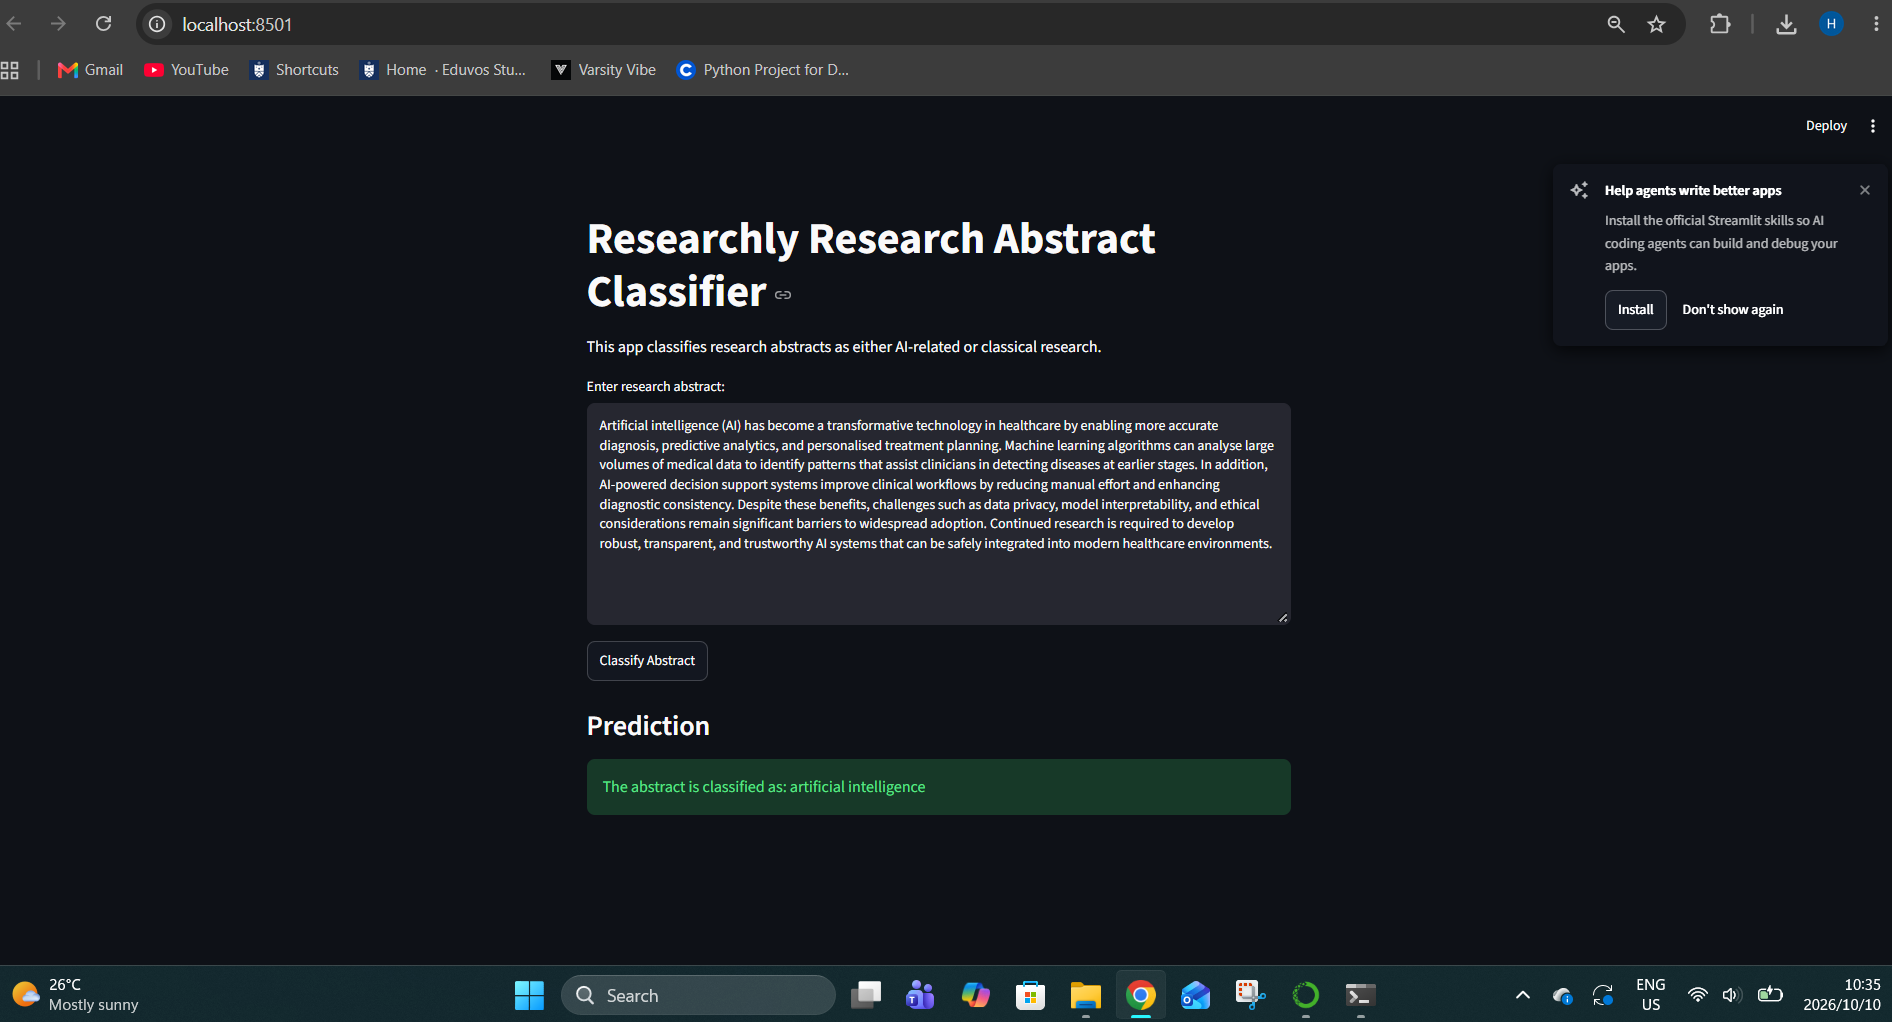

**2.3 Answer – deployment**

The best-performing configuration from 2.2 (a soft-voting ensemble of a calibrated Linear SVM, Gradient Boosting and Logistic Regression on TF-IDF features) was retrained on the full cleaned dataset and saved with `joblib` (`researchlyModel.pkl`). A Streamlit web app (`app.py`) loads the saved model. When a user enters an abstract and clicks "Classify Abstract", the app applies the same text-cleaning function used in 1.1 and passes the result to the model. It then displays the prediction as "artificial intelligence" or "classical research". The app is run locally with `streamlit run app.py`.

# References Used to help answer question 2

####  I also used AI (DeepSeek) to help me understand the questions and it also helped me formulate a response .I also used it to structure my code more neatly so that it is easier to read and understand.It also helped me interpret the output so that i could answer the following question based on the output of the previous

Akbari, K. (2024) VotingClassifier in Scikit-Learn: a comprehensive guide. Medium, 19 April. Available at: https://akbarikevin.medium.com/votingclassifier-in-scikit-learn-a-comprehensive-guide-c02bdc55f7f7 (Accessed: 10 October 2026).

scikit-learn developers (n.d.f) sklearn.ensemble. Available at: https://scikit-learn.org/stable/api/sklearn.ensemble.html (Accessed: 10 October 2026).

scikit-learn developers (n.d.g) sklearn.ensemble.VotingClassifier. Available at: https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.VotingClassifier.html (Accessed: 10 October 2026).

scikit-learn developers (n.d.h) sklearn.svm.LinearSVC. Available at: https://scikit-learn.org/1.4/modules/generated/sklearn.svm.LinearSVC.html (Accessed: 10 October 2026).

scikit-learn developers (n.d.i) User guide. Available at: https://scikit-learn.org/1.4/user_guide.html (Accessed: 10 October 2026).

Streamlit (n.d.) Caching overview. Available at: https://docs.streamlit.io/develop/concepts/architecture/caching (Accessed: 10 October 2026).